## Реализация метода Vanilla DQN в PyTorch

Реализуем метод **Vanilla DQN** для поиска оптимальной стратегии с приближением Q-функции на основе ИНС.

Значение Q-функции для состояния $s$ и действия $a$, которые выдаёт ИНС, будем обозначать $\widehat q(s,a,\theta_k)$, где $\theta_k$ - это текущие значения весов ИНС.
Для генерации траектории будем использовать $\varepsilon$-жадную стратегию на основе текущих значений Q-функции.  

Функция ошибки, минимизацию которой нужно проводить после каждого шага по траектории, имеет вид

$$
J(\theta_k) = (r + \gamma (1-terminated)  \max_a \widehat q(s',a,\theta_k) - \widehat q(s,a,\theta_k))^2,
$$
где $(s,a,r,s')$ - это информация о текущем положении на траектории, флаг $terminated$ является индикатором того, что $s'$ является терминальным состоянием текущего эпизода. Если флаг $terminated$ равен 1, то целью обновления является просто полученное вознаграждение $r$, так как терминальные состояния по умолчанию имеют ценность 0.

Шаг полуградиентного спуска имеет вид:
$$
\theta_{k+1} = \theta_k + \alpha \left(r + \gamma  (1-terminated) \max_a \widehat q(s',a,\theta_k) - \widehat q(s,a,\theta_k)\right) \, grad_\theta \widehat q(s,a,\theta_k)
$$



Как отмечено в лекциях, наличие следующих трёх факторов
    
- нелинейное приближение Q-функции
- использование разделённой стратегии
- формирование цели обновления с бутстреппингом     
    
одновременно затрудняют теоретическое ислледование гарантий сходимости. 

На практике, сходимость есть при аккуратном подборе гиперпараметров, но график функции ошибки отличается от типичного графика функции ошибки при обучении с учителем, а именно график не убывает к нулю, а сначала значения функции ошибки растут и лишь затем происходит убывание ошибки к нулю, возможно со значительными колебаниями.

In [1]:
import os 
os.environ["KMP_DUPLICATE_LIB_OK"]="TRUE"
# для избежания ошибки при отрисовки графиков
#https://programmerah.com/solved-omp-error-15-initializing-libiomp5md-dll-but-found-libiomp5md-dll-already-initialized-35360/

In [1]:
# Импорт нужных пакетов
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

import random
import time

from tqdm import tqdm

from abc import ABC, abstractmethod

При решении задач обучения с подкреплением методами типа DQN для каждой задачи подбирается своя конкретная структура сети для приближения Q-функции. Удобно создать класс, описывающий стуктуру сети.

В задачах, решаемых в этом Python-ноутбуке, состояние среды описывается вектором некоторой размерности. Отклик сети представляет собой также вектор с приближениями значений Q-функции для состояния $s$ на входе вида $(Q(s,a_1),...,Q(s,a_n))$, где $n$ равно количеству возможных действий. Пример ИНС для этого типа задач реализуем в классе `QNetwork`. Экземпляра этого класса с ИНС будем передаваться агенту.

In [2]:
class QNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        self.fc1 = nn.Linear(state_size, 64)
        self.fc2 = nn.Linear(64, 64)
        self.fc3 = nn.Linear(64, action_size)
        
    def forward(self, state):
        x = self.fc1(state)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.relu(x)
        return self.fc3(x)

Далее, требуется перевести данные, получаемые из метода `env.step()`, в формат тензоров. Это необходимо, поскольку все вычисления в `PyTorch` выполняются в тензорах. Причём, те данные, которые используются в вычислениях, надо перевести в тип данных `float`. Действия же нужно оставить в целочисленном типе данных, так как они будут использовать как индекс для получения нужного значения Q-функций из вектора значений Q-функции, полученного как выход ИНС.

In [3]:
def data_to_tensors(state, action, reward, next_state, terminated): 
    # перевод данных в тензоры
    state = torch.as_tensor(state, dtype=torch.float32)
    action = torch.as_tensor(action, dtype=torch.long) # будет использоваться как индекс
    reward = torch.as_tensor(reward, dtype=torch.float32)
    next_state = torch.as_tensor(next_state, dtype=torch.float32)
    terminated = torch.as_tensor(terminated, dtype=torch.float32)
    return state, action, reward, next_state, terminated
    # флаги переводим в float, а не в целые, так как terminated используется в вычислениях, 
    #в PyTorch все вычисления в float32
    
    return state, action, reward, next_state, terminated

Далее, напишем класс DQN-агента.

ИНС в `PyTorch` результат своей работы выдаёт также как тензор. При реализации методов `get_action()` и `best_action()` требуется вернуть действие по переданному состоянию `state`. Для этого вычисляется выход ИНС, будет получен тензор в виде вектора значений `q_values = [Q(s,a_1),...,Q(s,a_n)]`. Надо к этому вектору применить `torch.argmax(q_values)`, на выходе будет получен тензор размера 1 на 1 (даже если максимумов несколько), из которого надо извлечь значение методом `item()`

In [4]:
class QNetworkAgent(ABC):

    def __init__(self, env, model, alpha=0.001, gamma=0.99, epsilon=0.1):
        # инициализация полей
        self.alpha = alpha
        self.epsilon = epsilon
        self.gamma = gamma  
        self.nA = env.action_space.n

        # передача модели
        self.Q_train = model
        self.optimizer = torch.optim.Adam(self.Q_train.parameters(), lr=self.alpha)
        
        # для вывода графика изменения функции ошибки
        self.losses = []

    def best_action(self, state):
        # состояние в тензор
        state = torch.tensor(state).float()
        # вычисляем отклик ИНС, используем torch.no_grad(), чтобы не вычислялись градиенты  
        with torch.no_grad():
            q_values = self.Q_train(state)
        # жадный выбор
        return torch.argmax(q_values).item() 
        
    def get_action(self, state):
        if np.random.rand() < self.epsilon:
            return np.random.choice(self.nA)
        return self.best_action(state)
         
    def update(self, state, action, reward, next_state, terminated):
        # перевод данных в тензоры
        state, action, reward, next_state, terminated = data_to_tensors(state, action, reward, next_state, terminated)        

        # Находим max Q(s,a), вычисляя отклик ИНС без обучения, 
        with torch.no_grad():
            q_next_state = self.Q_train(next_state)
            q_target_next = q_next_state.max()
            q_target = reward + self.gamma * q_target_next * (1 - terminated)
        # Обучение: находим отклик ИНС на текущее состояние
        # из списка [Q(s,a1), Q(s,a2),...] выбираем Q(s,a) 
        # в соответствии с фактическими сделанным действием
        q_current = self.Q_train(state)[action]
        
        # функция ошибки и шаг градиентного спуска
        loss = F.mse_loss(q_current, q_target)
        self.losses.append(loss.item())
        
        self.optimizer.zero_grad()
        loss.backward()
        self.optimizer.step()

    @abstractmethod
    def learn(self):
        """Метод обучения"""
        pass

    def set_learning_rate(self, new_alpha: float):
        self.alpha = new_alpha
        for param_group in self.optimizer.param_groups:
            param_group['lr'] = new_alpha
        
    def play(self, env, n_episodes):
        for _ in tqdm(range(n_episodes)):
            state, _ = env.reset()
            while True:
                # выбираем лучшие действия
                action = self.best_action(state)
                state, reward, terminated, truncated, _ = env.step(action)
                if terminated or truncated:
                    break    
                
    def save_model(self, fname):
        torch.save(self.Q_train, 'savedModels/'+str(fname)+'.pkl')
        print("Net saved to: ", 'savedModels/'+str(fname)+'.pkl')
        
    def load_model(self, fname):
        self.Q_train = torch.load(fname, map_location=torch.device('cpu'), weights_only=False)
        self.Q_train.eval()
        print("Model loaded")

Теперь напишем управляющий алгоритм для метода DQN.

In [46]:
from dataclasses import dataclass

@dataclass
class ConfigTD:
    gamma: float = 0.99
    eps_start: float = 1.0
    eps_decay: float = 0.995
    eps_min: float = 0.01
    alpha_start: float = 0.1
    alpha_decay: float = 1.0
    alpha_min: float = 0.05


class DQN_Agent(QNetworkAgent): 
    def __init__(self, env, model = None, config = None):
        if model is None:
            model = QNetwork(env.observation_space.shape[0], env.action_space.n)
        super().__init__(env, model)
        if config is None:
            self.config = ConfigTD()
        else:
            self.config = config

            
        self.env = env
        self.alpha = self.config.alpha_start
        self.eps = self.config.eps_start
        self.gamma = self.config.gamma

    def learn(self, n_episodes = 1000, goal_score=200):

        # Инициализация   
        start_time = time.time()  # счётчик времени выполнения
        running_gain = goal_score - 1
        # ===== работа алгоритма обучения  =====

    
        for i in range(n_episodes):
            state, _ = env.reset()
            
            # запускаем эпизод взаимодействия со средой        
            while True:
                action = self.get_action(state)
                next_state, reward, terminated, truncated, _ = env.step(action)
                self.update(state, action, reward, next_state, terminated)
                state = next_state
                if terminated or truncated:
                    break
                    
            if i % 50 ==0:
                running_gain = np.mean(np.array(env.return_queue)[-100:])
                print("\rДоход: {:.2f} в эпизоде {}".format(running_gain, i))
                print("--- {} сек ---".format(time.time() - start_time))
                start_time = time.time()
    
            # выход из цикла при достижении целевого среднего дохода
            if running_gain > goal_score:  
                print("Успех на эпизоде {}!".format(i))
                break   
                
            # уменьшение доли шагов исследования
            self.eps = max(self.eps * self.config.eps_decay, self.config.eps_min)         
            self.alpha = max(self.alpha * self.config.alpha_decay, self.config.alpha_min)
            self.set_learning_rate(self.alpha)

In [20]:
def DQN_control(env, agent, num_episodes=10000,
                      eps_start=1.0, eps_decay = 0.995, eps_min = 0.01,
                       goal_score=200):

    # Инициализация   
    agent.epsilon = eps_start
    start_time = time.time()  # счётчик времени выполнения
    running_gain = goal_score - 1
    
    for i in range(num_episodes):
        state, _ = env.reset()
        
        # запускаем эпизод взаимодействия со средой        
        while True:
            action = agent.get_action(state)
            next_state, reward, terminated, truncated, _ = env.step(action)
            agent.update(state, action, reward, next_state, terminated)
            state = next_state
            if terminated or truncated:
                break
                
        # Снижение eps 
        agent.epsilon = max(agent.epsilon * eps_decay, eps_min)
             
        if i % 50 ==0:
            running_gain = np.mean(np.array(env.return_queue)[-100:])
            print("\rДоход: {:.2f} в эпизоде {}".format(running_gain, i))
            print("--- {} сек ---".format(time.time() - start_time))
            start_time = time.time()

        # выход из цикла при достижении целевого среднего дохода
        if running_gain > goal_score:  
            print("Успех на эпизоде {}!".format(i))
            break   

# Пример 1

Сначала рассмотрим работу метода DQN на примере задачи об обратном маятнике.

In [6]:
env = gym.make('CartPole-v1')
env = gym.wrappers.RecordEpisodeStatistics(env, 2000)

print('Размерность вектора состояний: ', env.observation_space.shape[0])
print('Количество действий: ', env.action_space.n)

Размерность вектора состояний:  4
Количество действий:  2


Формируем структуру сети и создаём два экзампляра. Используем ИНС с 1 слоем шириной 64 нейрона.

In [58]:
class QNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        #self.seed = torch.manual_seed(seed)
        self.fc1 = nn.Linear(state_size, 48)
        self.fc2 = nn.Linear(48, action_size)
        
    def forward(self, state):
        x = self.fc1(state)
        x = F.relu(x)
        return self.fc2(x)
    
model = QNetwork(env.observation_space.shape[0], env.action_space.n)

Задаём гиперпараметры, создаём агента.

In [59]:
env = gym.make('CartPole-v1')
n_episodes = 2000
env = gym.wrappers.RecordEpisodeStatistics(env, n_episodes)


config = ConfigTD(
    gamma = 0.99,
    eps_start = 1.0,
    eps_decay = 0.995,
    eps_min = 0.01,
    alpha_start = 0.05,
    alpha_decay = 0.99,
    alpha_min = 0.005,
               )

# создание табличного агента
agent = DQN_Agent(env, model, config)

Проверка работы получения действий

In [60]:
state, _ = env.reset()
action = 1
next_state, reward, done, _, _ = env.step(1)
next_state

array([-0.00274681,  0.19379574,  0.01222206, -0.32179752], dtype=float32)

In [25]:
print(agent.get_action(state))
print(agent.best_action(state))

0
0


In [51]:
agent.alpha

0.01

Проводим обучение.

In [61]:
# обучение агента и получение доходов по эпизодам
agent.learn(n_episodes = n_episodes, goal_score = 250);

Доход: 9.00 в эпизоде 0
--- 0.010779619216918945 сек ---
Доход: 13.08 в эпизоде 50
--- 0.6534824371337891 сек ---
Доход: 17.12 в эпизоде 100
--- 1.0194206237792969 сек ---
Доход: 31.12 в эпизоде 150
--- 1.9445788860321045 сек ---
Доход: 44.45 в эпизоде 200
--- 2.2474491596221924 сек ---
Доход: 48.03 в эпизоде 250
--- 2.2721800804138184 сек ---
Доход: 76.77 в эпизоде 300
--- 5.1080756187438965 сек ---
Доход: 103.15 в эпизоде 350
--- 5.010279655456543 сек ---
Доход: 144.96 в эпизоде 400
--- 9.194912195205688 сек ---
Доход: 157.87 в эпизоде 450
--- 6.138307571411133 сек ---
Доход: 132.58 в эпизоде 500
--- 6.6713340282440186 сек ---
Доход: 132.91 в эпизоде 550
--- 6.297494649887085 сек ---
Доход: 100.08 в эпизоде 600
--- 3.479490280151367 сек ---
Доход: 125.98 в эпизоде 650
--- 8.815902471542358 сек ---
Доход: 302.06 в эпизоде 700
--- 20.669198513031006 сек ---
Успех на эпизоде 700!


Обученные параметры можно сохранить. Выведем также график доходов по эпизодам обучения и график изменения значений функции ошибки.

In [67]:
agent.save_model("VanillaDQN_CartPole_64neurons")

Net saved to:  savedModels/VanillaDQN_CartPole_64neurons.pkl


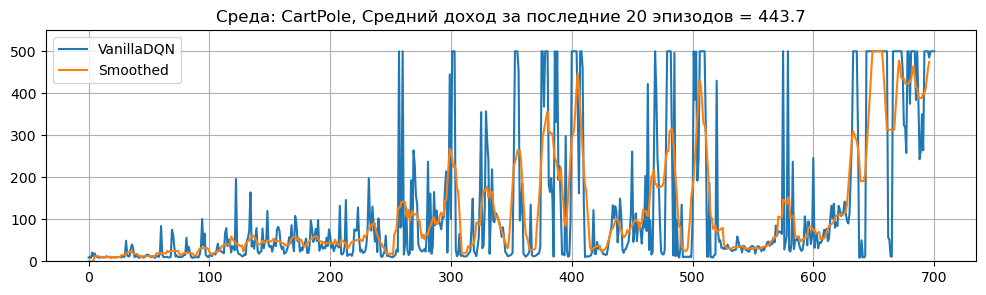

In [62]:
def plot_rewards(env_name, returns, label):
    # сглаженный вектор доходов
    returns_smoothed = np.pad(np.convolve(returns, np.ones(10)/10, mode='valid'),[5, 0])
    fig = plt.figure(figsize=(12, 3))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.plot(returns_smoothed, label="Smoothed")
    plt.grid()
    plt.legend()
    plt.ylim(0, 550)
    plt.show()

returns = np.array(env.return_queue)
plot_rewards("CartPole", returns, 'VanillaDQN')

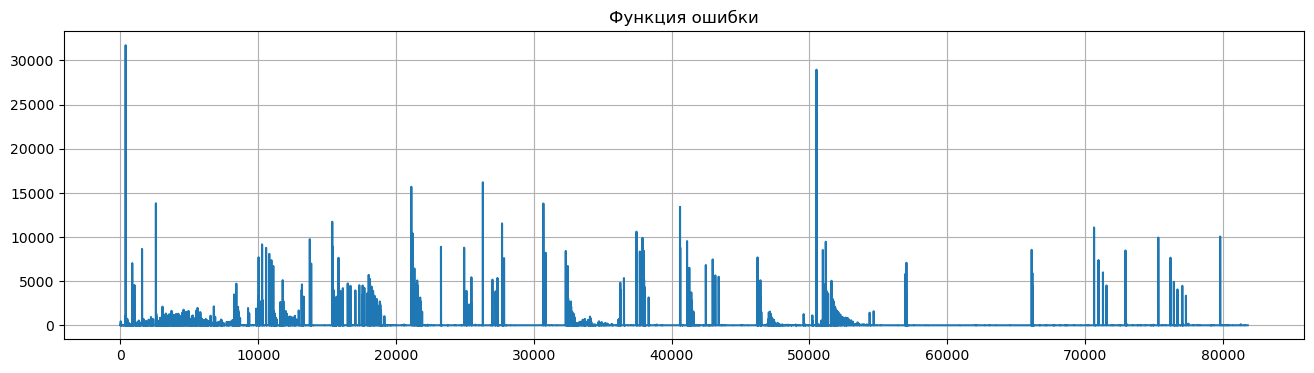

In [63]:
fig = plt.figure(figsize=(16, 4))
plt.title("Функция ошибки")
plt.plot(agent.losses)
plt.grid()
plt.show()

Ниже можно запустить 100 эпизодов симуляции работы обученного агента.

In [68]:
# можно подгрузить обученные веса
agent = DQN_Agent(env, model, config)
agent.load_model('savedModels/VanillaDQN_CartPole_64neurons.pkl')

Model loaded


In [69]:
# создание экземпляра среды
env = gym.make('CartPole-v1')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,100)

print("Средний доход: ", np.mean(env.return_queue))
print("Минимальный доход: ", np.min(env.return_queue))

100%|██████████| 100/100 [00:05<00:00, 18.25it/s]

Средний доход:  500.0
Минимальный доход:  500.0


In [70]:
# демонстрация работы агента
env = gym.make('CartPole-v1', render_mode='human')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,1)
print("Число шагов:", env.return_queue[-1])

env.close()

100%|██████████| 1/1 [00:10<00:00, 10.39s/it]

Число шагов: 500.0


# Пример 2

Рассмотрим задачу о посадке лунного модуля. У модуля есть 3 двигателя, которые он может включать или выключать. Таким образом модулю имеет 4 действия:

    0 ничего не делать
    1. включить левый двигатель
    2. включить центральный двигатель
    3. включить правый двигатель

Топливо бесконечное. Пространство состояний представляет собой 8-ми мерный вектор, каждая координата отвечает за следующие величины

    0. положение по оси Ox
    1. положение по оси Oy
    2. линейная скорость по оси Ox
    3. линейная скорость по оси Oy
    4. угол отклонения оси модуля от вертикали
    5. скорость изменения угла
    6. флаг о касании Луны левой ноги модуля
    7. флаг о касании Луны правой ноги модуля
    
Вознаграждение даётся за каждый временной шаг.

    вознаграждение увеличивается/уменьшается за сближение/удаление с посадочной площадкой
    вознаграждение увеличивается/уменьшается за более медленное/быстрое движение
    вознаграждение уменьшается за сильное отклонения угла от нулевого.
    вознаграждение увеличивается на 10 за конкакт одной ноги с поверхностью
    вознаграждение уменьшается на 0.03 за каждый временной шаг работы боковых двигателей
    вознаграждение уменьшается на 0.3 за каждый временной шаг работы центрального двигателей

За успешную посадку даётся +100. За разбитый модулю даётся -100.
Задача считается завершённой с числом очков равным 200.

Начальное состояние в положениии вверху по центру кадра со случайной начальной силой, приложенной к центру масс. 

Эпизод завершается, если модуль коснулся поверхностью не ногами (то есть модуль разбился), или если модуль улетел за допустимую область.

По ссылке в описании среды можно также дополнительно активировать ряд условий, таких как наличие ветра, изменённой гравитации, турбулентность и пр.
https://gymnasium.farama.org/environments/box2d/lunar_lander/

Для установки на Win:
    
    надо установить Microsoft Visual C++ 2014 или выше, Windows SDK для соответствующей версии Windows
    далее, надо установить бибилотеки swig и box2d-py, это можно сделать командами:
    pip install swig
    pip install box2d-py

In [73]:
env = gym.make('LunarLander-v3')

print('Размерность вектора состояний: ', env.observation_space.shape[0])
print('Количество действий: ', env.action_space.n)

Размерность вектора состояний:  8
Количество действий:  4


Поскольку в сравнении с задачей о маятнике, здесь вектор состояний больше и число действией больше, то используем сеть, где в скрытом слое 128 нейронов.


In [83]:
class QNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        #self.seed = torch.manual_seed(seed)
        self.fc1 = nn.Linear(state_size, 128)
        self.fc2 = nn.Linear(128, action_size)
        
    def forward(self, state):
        x = self.fc1(state)
        x = F.relu(x)
        return self.fc2(x)
    
model = QNetwork(env.observation_space.shape[0], env.action_space.n)

In [84]:
env = gym.make('LunarLander-v3')
env = gym.wrappers.RecordEpisodeStatistics(env, 3000)

config = ConfigTD(
    gamma = 0.99,
    eps_start = 1.0,
    eps_decay = 0.998,
    eps_min = 0.01,
    alpha_start = 0.02,
    alpha_decay = 0.995,
    alpha_min = 0.001,
               )

agent = DQN_Agent(env, model, config)

In [85]:
s, _ = env.reset()
print(s)

agent.get_action(s)

[ 0.00619631  1.4124986   0.6276032   0.07014599 -0.00717319 -0.14216143
  0.          0.        ]


0

In [86]:
agent.learn(n_episodes = 1500, goal_score = 180)

Доход: -445.12 в эпизоде 0
--- 0.1161038875579834 сек ---
Доход: -154.65 в эпизоде 50
--- 7.786026954650879 сек ---
Доход: -134.89 в эпизоде 100
--- 13.457343578338623 сек ---
Доход: -77.42 в эпизоде 150
--- 19.040203094482422 сек ---
Доход: 32.82 в эпизоде 200
--- 22.01344633102417 сек ---
Доход: 60.70 в эпизоде 250
--- 25.268115043640137 сек ---
Доход: 45.66 в эпизоде 300
--- 26.7924222946167 сек ---
Доход: 86.10 в эпизоде 350
--- 33.665355920791626 сек ---
Доход: 118.99 в эпизоде 400
--- 28.539125442504883 сек ---
Доход: 94.71 в эпизоде 450
--- 28.815447568893433 сек ---
Доход: 96.34 в эпизоде 500
--- 31.28737211227417 сек ---
Доход: 128.45 в эпизоде 550
--- 36.70333981513977 сек ---
Доход: 116.77 в эпизоде 600
--- 30.885419368743896 сек ---
Доход: 123.19 в эпизоде 650
--- 27.330538988113403 сек ---
Доход: 140.21 в эпизоде 700
--- 28.52319574356079 сек ---
Доход: 146.33 в эпизоде 750
--- 27.088892936706543 сек ---
Доход: 149.55 в эпизоде 800
--- 20.687803983688354 сек ---
Доход: 126

In [92]:
agent.save_model("VanillaDQN_LunarLander_128neurons")

Net saved to:  savedModels/VanillaDQN_LunarLander_128neurons.pkl


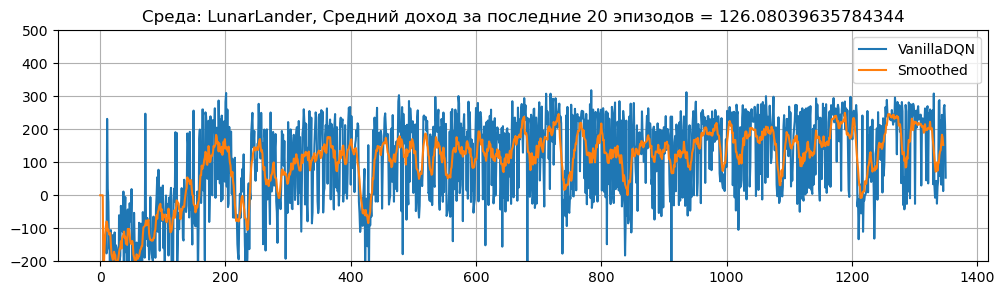

In [87]:
def plot_rewards(env_name, returns, label):
    # сглаженный вектор доходов
    returns_smoothed = np.pad(np.convolve(returns, np.ones(10)/10, mode='valid'),[5, 0])
    fig = plt.figure(figsize=(12, 3))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.plot(returns_smoothed, label="Smoothed")
    plt.grid()
    plt.legend()
    plt.ylim(-200,500)
    plt.show()

returns = np.array(env.return_queue)
plot_rewards("LunarLander", returns, 'VanillaDQN')

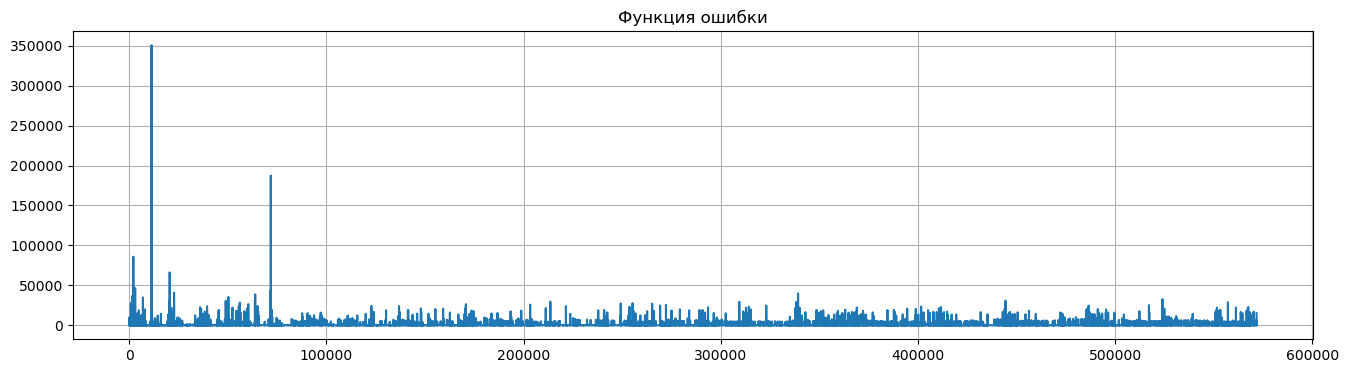

In [88]:
fig = plt.figure(figsize=(16, 4))
plt.title("Функция ошибки")
plt.plot(agent.losses)
plt.grid()
plt.show()

Ниже можно запустить 100 эпизодов симуляции работы обученного агента.

In [93]:
# можно подгрупзить обученные веса
agent = DQN_Agent(env, model, config)
agent.load_model("savedModels/VanillaDQN_LunarLander_128neurons.pkl")

Model loaded


In [94]:
# создание экземпляра среды
env = gym.make('LunarLander-v3')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,100)

print("Средний доход: ", np.mean(env.return_queue))
print("Минимальный доход: ", np.min(env.return_queue))

100%|██████████| 100/100 [00:04<00:00, 20.12it/s]

Средний доход:  220.3221932395794
Минимальный доход:  -36.88453560596814


Запуск симуляции с обученным агентом.

In [90]:
# создание экземпляра среды
env = gym.make('LunarLander-v3', render_mode='human')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,1)
print("Число шагов:", env.return_queue[-1])

env.close()

100%|██████████| 1/1 [00:07<00:00,  7.48s/it]

Число шагов: 286.7810964793865


### Пример 3.

Рассмотрим задачу о машинке и холме MountainCar. Структуру ИНС используем ту же самую.

In [97]:
env = gym.make('MountainCar-v0', max_episode_steps=500)
env = gym.wrappers.RecordEpisodeStatistics(env, 2000)

print('Размерность вектора состояний: ', env.observation_space.shape[0])
print('Количество действий: ', env.action_space.n)

Размерность вектора состояний:  2
Количество действий:  3


In [98]:
class QNetwork(nn.Module):
    def __init__(self, state_size, action_size):
        super(QNetwork, self).__init__()
        #self.seed = torch.manual_seed(seed)
        self.fc1 = nn.Linear(state_size, 96)
        self.fc2 = nn.Linear(96, action_size)
        
    def forward(self, state):
        x = self.fc1(state)
        x = F.relu(x)
        return self.fc2(x)
    
model = QNetwork(env.observation_space.shape[0], env.action_space.n)

In [99]:
env = gym.make('MountainCar-v0', max_episode_steps=500)
env = gym.wrappers.RecordEpisodeStatistics(env, 2000)

config = ConfigTD(
    gamma = 0.99,
    eps_start = 1.0,
    eps_decay = 0.998,
    eps_min = 0.01,
    alpha_start = 0.05,
    alpha_decay = 1,
    alpha_min = 0.01,
               )

agent = DQN_Agent(env, model, config)

In [100]:
s, _ = env.reset()
print(s)

agent.get_action(s)

[-0.524664  0.      ]


1

In [101]:
agent.learn(n_episodes = 1500, goal_score = -130)

Доход: -500.00 в эпизоде 0
--- 0.7647526264190674 сек ---
Доход: -491.94 в эпизоде 50
--- 39.379581451416016 сек ---
Доход: -495.89 в эпизоде 100
--- 50.473527908325195 сек ---
Доход: -497.23 в эпизоде 150
--- 63.647217988967896 сек ---
Доход: -481.63 в эпизоде 200
--- 56.35786271095276 сек ---
Доход: -441.18 в эпизоде 250
--- 49.095120668411255 сек ---
Доход: -433.23 в эпизоде 300
--- 43.40536832809448 сек ---
Доход: -438.70 в эпизоде 350
--- 30.23191738128662 сек ---
Доход: -461.25 в эпизоде 400
--- 31.951273441314697 сек ---
Доход: -499.00 в эпизоде 450
--- 26.630915880203247 сек ---
Доход: -500.00 в эпизоде 500
--- 25.96315622329712 сек ---
Доход: -500.00 в эпизоде 550
--- 26.332369565963745 сек ---
Доход: -500.00 в эпизоде 600
--- 25.985397338867188 сек ---
Доход: -500.00 в эпизоде 650
--- 25.53707265853882 сек ---
Доход: -500.00 в эпизоде 700
--- 31.66799807548523 сек ---
Доход: -500.00 в эпизоде 750
--- 49.811015367507935 сек ---
Доход: -500.00 в эпизоде 800
--- 69.2496068477630

Как видно из печатаемой информации, обучение агента в этой задаче не достигает успеха. Действительно, здесь система вознаграждений весьма скудная и не позволяет агенту, обучаемому по методу DQN, выявить правильные действия.

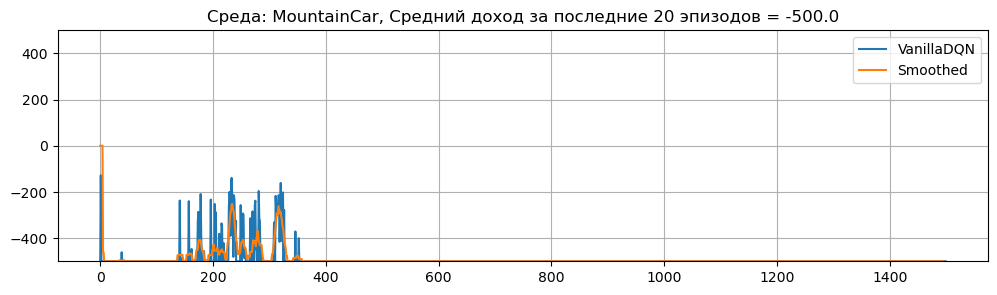

In [102]:
def plot_rewards(env_name, returns, label):
    # сглаженный вектор доходов
    returns_smoothed = np.pad(np.convolve(returns, np.ones(10)/10, mode='valid'),[5, 0])
    fig = plt.figure(figsize=(12, 3))
    plt.title("Среда: "+env_name+", Средний доход за последние 20 эпизодов = "+str(np.mean(returns[-20:])))
    plt.plot(returns, label=label)
    plt.plot(returns_smoothed, label="Smoothed")
    plt.grid()
    plt.legend()
    plt.ylim(-500,500)
    plt.show()

returns = np.array(env.return_queue)
plot_rewards("MountainCar", returns, 'VanillaDQN')

In [103]:
env = gym.make('MountainCar-v0', max_episode_steps=500)
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,100)

print("Средний доход: ", np.mean(env.return_queue))
print("Минимальный доход: ", np.min(env.return_queue))

100%|██████████| 100/100 [00:05<00:00, 17.63it/s]

Средний доход:  -500.0
Минимальный доход:  -500.0


In [17]:
# создание экземпляра среды
env = gym.make('MountainCar-v0', render_mode='human')
env = gym.wrappers.RecordEpisodeStatistics(env)

agent.play(env,1)
print("Число шагов:", env.return_queue[-1])

env.close()

Доход: -200.0
